In [6]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [7]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle
import cv2
from skimage.transform import resize

In [59]:
mov_ind = 4

In [60]:
# Load in movie as dataset
mov_filenames = ['tree', 'water', 'grasses', 'fish', 'opticflow']
mov_path = os.path.join(project_folder, 'data', f'MultipleMoviesStim_{mov_ind+1}_{mov_filenames[mov_ind]}.avi')

cap = cv2.VideoCapture(mov_path)
frames = []
grays = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    grays.append(gray)
    frames.append(gray.flatten().astype(float))
cap.release()

mov_dims = gray.shape
frame_H, frame_W = mov_dims
mov_array = np.array(frames).T  # (H*W, n_frames)

M = ds.Dataset(mov_array)
print(f'Movie shape (pixels x frames): {M.X.shape}')

Movie shape (pixels x frames): (118336, 1200)


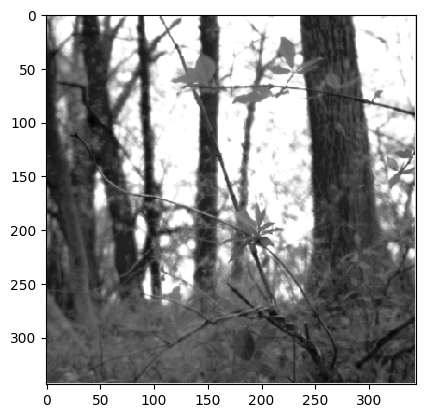

In [61]:
plt.imshow(grays[-1], cmap='Greys_r')

In [62]:
F = np.load(project_folder + '/data/kyle_filters.npy')

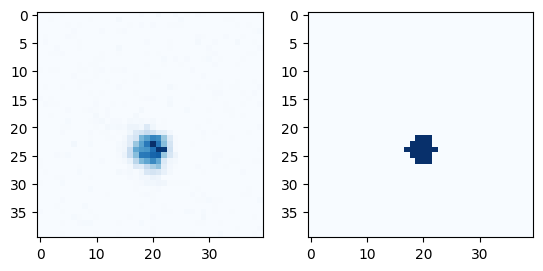

In [63]:
thresh = 0.5

f = F[...,-1].T    # 40 x 40 array, indices x, y
f2max = np.max(f**2)
fig, ax = plt.subplots(ncols=2)
ax[0].imshow(f**2, cmap='Blues')
ax[1].imshow(f**2 > thresh * f2max, cmap='Blues')

In [64]:
f_rescaled = resize(f, mov_dims, anti_aliasing=True, preserve_range=True) # rescale array to size 
mov_mask = f_rescaled**2 > thresh * f2max

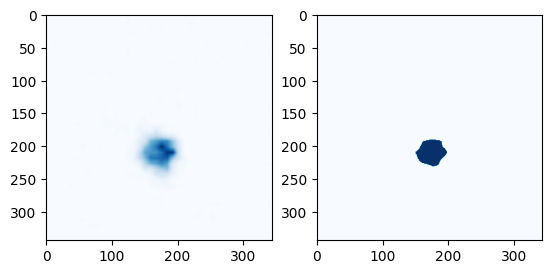

In [65]:
fig, ax = plt.subplots(ncols=2)
ax[0].imshow(f_rescaled**2, cmap='Blues')
ax[1].imshow(mov_mask, cmap='Blues')

In [66]:
# Create new dataset for masked movie data
M_masked = ds.Dataset(M.X[mov_mask.flatten(), :])  # (N_masked_pixels, T)
M_masked.frame_dims = mov_dims
M_masked.frame_H = frame_H
M_masked.frame_W = frame_W
print(f'Masked movie shape: {M_masked.X.shape}')

Masked movie shape: (1364, 1200)


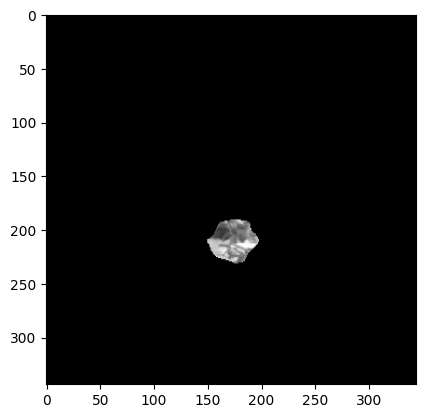

In [67]:
plt.imshow(mov_mask.reshape(*mov_dims) * grays[0], cmap='Greys_r')

# Loop through

In [71]:
mov_filenames = ['tree', 'water', 'grasses', 'fish', 'opticflow']
thresh = 0.8

for mov_ind in range(5):
    # Load in movie as dataset
    mov_path = os.path.join(project_folder, 'data', f'MultipleMoviesStim_{mov_ind+1}_{mov_filenames[mov_ind]}.avi')
    cap = cv2.VideoCapture(mov_path)
    frames = []
    grays = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        grays.append(gray)
        frames.append(gray.flatten().astype(float))
    cap.release()

    mov_dims = gray.shape
    frame_H, frame_W = mov_dims
    mov_array = np.array(frames).T  # (H*W, n_frames)

    M = ds.Dataset(mov_array)
    # print(f'Movie shape (pixels x frames): {M.X.shape}')

    # Make mask
    f = F[...,-1].T    # 40 x 40 array, indices x, y
    f2max = np.max(f**2)
    # fig, ax = plt.subplots(ncols=2)
    # ax[0].imshow(f**2, cmap='Blues')
    # ax[1].imshow(f**2 > thresh * f2max, cmap='Blues')
    f_rescaled = resize(f, mov_dims, anti_aliasing=True, preserve_range=True) # rescale array to size 
    mov_mask = f_rescaled**2 > thresh * f2max

    # Create new dataset for masked movie data
    M_masked = ds.Dataset(M.X[mov_mask.flatten(), :])  # (N_masked_pixels, T)
    M_masked.frame_dims = mov_dims
    M_masked.frame_H = frame_H
    M_masked.frame_W = frame_W
    print(f'Masked movie shape: {M_masked.X.shape}')

    
    # Save masked movie dataset
    os.makedirs(save_directory, exist_ok=True)
    save_path = os.path.join(save_directory, f'M_masked_mov{mov_ind}_thresh{thresh}.pkl')
    M_masked.save(save_path)
    print(f'Saved to {save_path}')


Masked movie shape: (253, 600)
Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov0_thresh0.8.pkl
Masked movie shape: (253, 1200)
Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov1_thresh0.8.pkl
Masked movie shape: (253, 1200)
Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov2_thresh0.8.pkl
Masked movie shape: (253, 1200)
Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov3_thresh0.8.pkl
Masked movie shape: (253, 1200)
Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov4_thresh0.8.pkl
